# 01 &nbsp;What are we testing, and on what data?

**The problem.** A retrieval-augmented generation (RAG) system has a handful of knobs: how big the chunks are, which model finds them, whether a second model reranks them, and how many go into the prompt. Teams usually keep the defaults from a tutorial. Each knob changes both answer quality and cost, and nobody measures which ones are worth paying for.

**The approach.** A fixed, small grid of 54 configurations, run on two public question-answering datasets with known answers, with one answer model. The plan, including the findings to test and how, was written down in [`plans/analysis_plan.md`](../plans/analysis_plan.md) before any answers were generated.

This notebook looks at the data before any model runs:

1. The two datasets and what makes each one hard.
2. How far a model gets by **guessing**, without reading anything. Every configuration has to beat that.
3. The fixed question sample, and whether it is big enough to tell configurations apart.
4. What the chunk sizes do to the documents, and one trap in a popular embedding model.

In [1]:
import re
import warnings

warnings.filterwarnings("ignore", message="urllib3 v2 only supports OpenSSL")  # old SSL on macOS system Python

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import evalsize as es
from transformers import AutoTokenizer, logging as hf_logging

from ragdecisions import style
from ragdecisions.chunking import chunk_spans, evidence_found
from ragdecisions.data import DATASETS, RESULTS_DIR, load_corpus, load_questions, sample_questions
from ragdecisions.grid import CHUNK_SIZES, TOP_K
from ragdecisions.metrics import normalize_text as normalize

hf_logging.set_verbosity_error()
style.use_style()
pd.set_option("display.max_colwidth", 80)

corpus = {name: load_corpus(name) for name in DATASETS}
questions = {name: load_questions(name) for name in DATASETS}

## 1. Two datasets, two kinds of difficulty

**MultiHop-RAG** was built to test RAG systems: news articles from September to December 2023, and questions whose evidence is spread over two to four articles. It also gives the exact evidence sentences, so we can check whether retrieval found them. **Natural Questions** uses real Google searches answered from full Wikipedia pages. Both have long documents, so chunk size matters, and short answers, so grading is reliable.

In [2]:
def words(text):
    return len(text.split())

summary = pd.DataFrame({
    DATASETS[name]: {
        "Documents": len(corpus[name]),
        "Median words per document": int(corpus[name]["text"].map(words).median()),
        "Total words": int(corpus[name]["text"].map(words).sum()),
        "Questions": len(questions[name]),
        "License": {"multihop_rag": "ODC-BY", "natural_questions": "CC BY-SA 3.0"}[name],
    }
    for name in DATASETS
})
summary

,MultiHop-RAG,Natural Questions
Documents,609,2147
Median words per document,1298,4023
Total words,1063319,12594033
Questions,2556,1026
License,ODC-BY,CC BY-SA 3.0


In [3]:
mhr = questions["multihop_rag"]
mhr["answer"] = mhr["answers"].str[0]
mhr["evidence_count"] = mhr["gold"].map(len)
pd.crosstab(mhr["type"], mhr["evidence_count"], margins=True, margins_name="All")

evidence_count,0,2,3,4,All
type,,,,,
comparison,0,658,198,0,856
inference,0,103,315,398,816
null,301,0,0,0,301
temporal,0,318,265,0,583
All,301,1079,778,398,2556


Questions the articles cannot answer (`null`) have no evidence; the right reply is to say there is not enough information. Every other question needs two to four pieces of evidence, often from different news sources.

## 2. How far does guessing get?

A grid of RAG settings means little if a model can score well without reading. MultiHop-RAG's answers are lopsided, so the first floor is a model that never reads and always gives the most common answer for each question type. The type is easy to tell from the wording: comparison and temporal questions ask for yes or no, inference questions ask who or what.

Questions the articles cannot answer are left out of this floor and out of the main accuracy measure. They look like inference questions, so a guesser cannot spot them, and the risk they test is different: answering when the model should decline. They get their own measure, the share answered anyway, in notebook 03.

In [4]:
mhr["answer_norm"] = mhr["answer"].map(normalize)
shares = mhr["answer_norm"].value_counts(normalize=True)
print(f"Yes or no: {shares.get('yes', 0) + shares.get('no', 0):.0%} of answers")
print(f"Not answerable: {shares.get('insufficient information', 0):.0%}")
print(f"Sam Bankman-Fried and Google together: {shares.get('sam bankman fried', 0) + shares.get('google', 0):.0%}")

answerable = mhr[mhr["type"] != "null"].copy()
most_common = answerable.groupby("type")["answer_norm"].agg(lambda s: s.value_counts().index[0])
answerable["guess_right"] = answerable["answer_norm"] == answerable["type"].map(most_common)
by_type = answerable.groupby("type").agg(questions=("qid", "size"), guess=("answer_norm", lambda s: s.value_counts().index[0]),
                                  guess_right=("guess_right", "mean"))
guess_floor = answerable["guess_right"].mean()
by_type

Yes or no: 53% of answers
Not answerable: 12%
Sam Bankman-Fried and Google together: 19%


,questions,guess,guess_right
type,,,
comparison,856,yes,0.598131
inference,816,sam bankman fried,0.337010
temporal,583,yes,0.463122


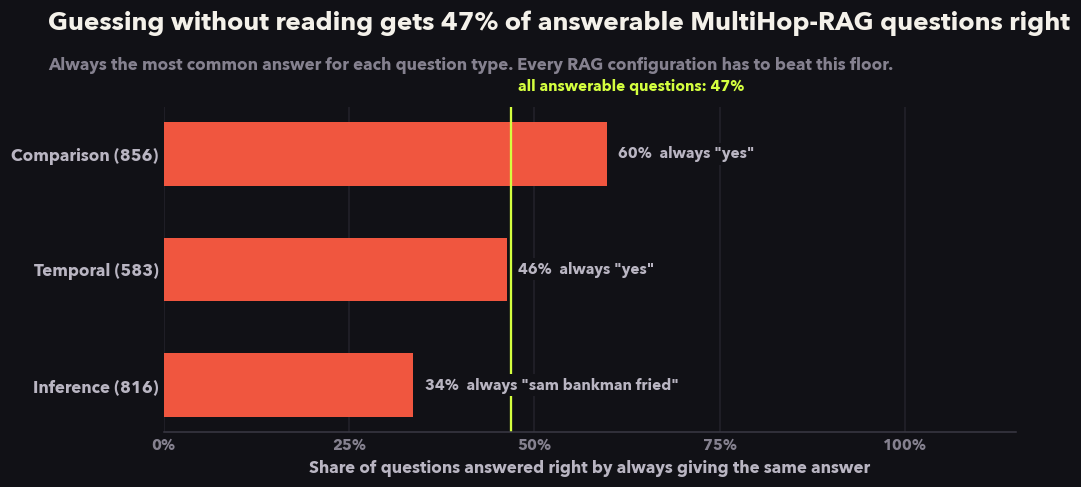

In [5]:
type_labels = {"comparison": "Comparison", "inference": "Inference", "temporal": "Temporal"}
order = by_type["guess_right"].sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(order))
ax.barh(y, by_type.loc[order, "guess_right"], color=style.DATASET_COLORS["multihop_rag"], height=0.55)
for i, t in enumerate(order):
    ax.text(by_type.loc[t, "guess_right"] + 0.015, i, f"{by_type.loc[t, 'guess_right']:.0%}  always \"{by_type.loc[t, 'guess']}\"",
            va="center", color=style.INK_2, fontsize=10, zorder=3,
            bbox=dict(facecolor=style.SURFACE, edgecolor="none", pad=2))
ax.axvline(guess_floor, color=style.HIGHLIGHT, lw=1.5)
ax.text(guess_floor + 0.01, len(order) - 0.45, f"all answerable questions: {guess_floor:.0%}", color=style.HIGHLIGHT, fontsize=10)
ax.set_yticks(y, [f"{type_labels[t]} ({by_type.loc[t, 'questions']:,})" for t in order])
ax.set_xlim(0, 1.15)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("Share of questions answered right by always giving the same answer")
style.headline(fig, f"Guessing without reading gets {guess_floor:.0%} of answerable MultiHop-RAG questions right",
               "Always the most common answer for each question type. Every RAG configuration has to beat this floor.")
fig.subplots_adjust(top=0.78)
style.save(fig, "guess_floor")
plt.show()

That floor is high because yes or no answers make up half the dataset and two names answer one question in five. Accuracy on MultiHop-RAG is therefore reported **against this floor and by question type**, never as a bare number. The second floor, the same model answering with no documents at all, is measured in notebook 03 once answers exist.

Natural Questions has no such shortcut: answers are mostly names, dates and numbers, spread over hundreds of topics.

In [6]:
nq = questions["natural_questions"]
nq_text = dict(zip(corpus["natural_questions"]["doc_id"], corpus["natural_questions"]["text"].map(normalize)))
nq_first = nq["answers"].str[0].map(normalize)
pd.Series({
    "Questions with a short answer": len(nq),
    "Accepted answers per question (median)": int(nq["answers"].map(len).median()),
    "Words in the first answer (median)": int(nq_first.str.split().map(len).median()),
    "Most common answer, share of questions": f"{nq_first.value_counts(normalize=True).iloc[0]:.1%}",
    "Questions whose answer appears in the gold page": f"{np.mean([any(normalize(a) in nq_text[g[0]['doc_id']] for a in ans) for ans, g in zip(nq['answers'], nq['gold'])]):.1%}",
}, name="Natural Questions").to_frame()

,Natural Questions
Questions with a short answer,1026
Accepted answers per question (median),1
Words in the first answer (median),2
"Most common answer, share of questions",0.6%
Questions whose answer appears in the gold page,98.9%


## 3. The fixed sample, and whether it is big enough

Every answer costs time, so the study uses a fixed sample: 300 MultiHop-RAG questions, keeping each type's share, and 200 Natural Questions. The sample is drawn once with a fixed seed and saved, so every configuration answers exactly the same questions and comparisons are paired.

In [7]:
sample = {
    "multihop_rag": sample_questions(questions["multihop_rag"], n=300, strata="type", seed=7),
    "natural_questions": sample_questions(questions["natural_questions"], n=200, strata="type", seed=7),
}
RESULTS_DIR.mkdir(exist_ok=True)
pd.concat([s[["qid", "type"]].assign(dataset=name) for name, s in sample.items()])[["dataset", "qid", "type"]] \
    .to_csv(RESULTS_DIR / "question_sample.csv", index=False)

pd.DataFrame({
    "In the full set": questions["multihop_rag"]["type"].value_counts(normalize=True),
    "In the sample of 300": sample["multihop_rag"]["type"].value_counts(normalize=True),
}).style.format("{:.1%}")

,In the full set,In the sample of 300
type,,
comparison,33.5%,33.7%
inference,31.9%,32.0%
temporal,22.8%,22.7%
null,11.8%,11.7%


How small a difference can the sample detect? Accuracy on MultiHop-RAG is measured on its answerable questions, so the count that matters is a little below 300. The answer also depends on how often two configurations disagree on a question. Assuming accuracy near 60% and disagreement on 15% of questions (both checked once answers exist), [evalsize](https://github.com/ai-with-md/evalsize) gives the smallest difference in accuracy the sample can reliably detect, with 80% power at the 5% level.

In [8]:
n_answerable = int((sample["multihop_rag"]["type"] != "null").sum())
sizes = {f"MultiHop-RAG, {n_answerable} answerable": n_answerable, "Natural Questions, 200": 200}
detectable = pd.DataFrame({
    label: {f"{d:.0%} disagreement": es.smallest_detectable_improvement(n=n, baseline=0.6, disagreement=d)
            for d in [0.10, 0.15, 0.25]}
    for label, n in sizes.items()
})
detectable.style.format("{:.1%}")

,"MultiHop-RAG, 265 answerable","Natural Questions, 200"
10% disagreement,5.4%,6.2%
15% disagreement,6.6%,7.6%
25% disagreement,8.6%,9.8%


On MultiHop-RAG's 265 answerable questions, differences of about **7 points** are detectable; on 200 Natural Questions, about **8 points**. Smaller differences may be real but will show up as "not distinguishable", and the decision section treats them that way rather than picking a winner by noise.

## 4. What chunk size does to the documents

Chunk sizes are counted in tokens of the BERT tokenizer that all three embedding models share, with room for its two special tokens. Whole sentences are packed into each chunk until the next one would not fit.

In [9]:
tokenizer = AutoTokenizer.from_pretrained("BAAI/bge-base-en-v1.5")

def count(text):
    return len(tokenizer(text, add_special_tokens=False)["input_ids"])

chunks = {}
for name in DATASETS:
    for size in CHUNK_SIZES:
        rows = []
        for doc_id, text in zip(corpus[name]["doc_id"], corpus[name]["text"]):
            for start, end in chunk_spans(text, size - 2, count):
                rows.append((doc_id, start, end, count(text[start:end])))
        chunks[name, size] = pd.DataFrame(rows, columns=["doc_id", "start", "end", "tokens"])

chunk_table = pd.DataFrame({
    (DATASETS[name], f"{size}"): {
        "Chunks": len(chunks[name, size]),
        "Average tokens per chunk": round(chunks[name, size]["tokens"].mean()),
        "Over 254 tokens (MiniLM cuts these)": f"{(chunks[name, size]['tokens'] > 254).mean():.0%}",
    }
    for name in DATASETS for size in CHUNK_SIZES
})
chunk_table

MultiHop-RAG              \
                                             128   256   512   
Chunks                                     13074  6216  3147   
Average tokens per chunk                     108   227   449   
Over 254 tokens (MiniLM cuts these)           0%    0%   91%   

                                    Natural Questions                
                                                  128    256    512  
Chunks                                         155605  73635  36229  
Average tokens per chunk                          112    238    483  
Over 254 tokens (MiniLM cuts these)                0%     0%    97%

**A trap in a popular default.** all-MiniLM-L6-v2, the most downloaded sentence embedding model, reads at most 256 tokens and silently drops the rest. With 512-token chunks it never sees the second half of over 90% of chunks, so a fact there cannot be found by meaning. The grid keeps this combination on purpose, because it is a setup people actually run.

Larger chunks are also more likely to keep each evidence sentence in one piece. For the sampled MultiHop-RAG questions:

In [10]:
def evidence_whole(name, size):
    spans = chunks[name, size].groupby("doc_id")[["start", "end"]].apply(lambda d: list(zip(d["start"], d["end"])))
    whole = []
    for gold in sample[name]["gold"]:
        for ev in gold:
            whole.append(any(s <= ev["start"] and ev["end"] <= e for s, e in spans[ev["doc_id"]]))
    return np.mean(whole)

pd.Series({f"{size} tokens": f"{evidence_whole('multihop_rag', size):.1%}" for size in CHUNK_SIZES},
          name="Evidence sentences inside a single chunk").to_frame().T

,128 tokens,256 tokens,512 tokens
Evidence sentences inside a single chunk,99.9%,100.0%,100.0%


Almost every evidence sentence sits whole inside one chunk at every size, so chunk size will not change results by cutting evidence in half. Its effect has to come from somewhere else: how much surrounding text comes along, and how precisely a chunk can be matched to a question.

## 5. Prompt size, the main driver of cost

The answer model reads every retrieved passage. Prompt size, chunk size times the number of passages, decides most of the cost per answer, and it varies widely across the grid.

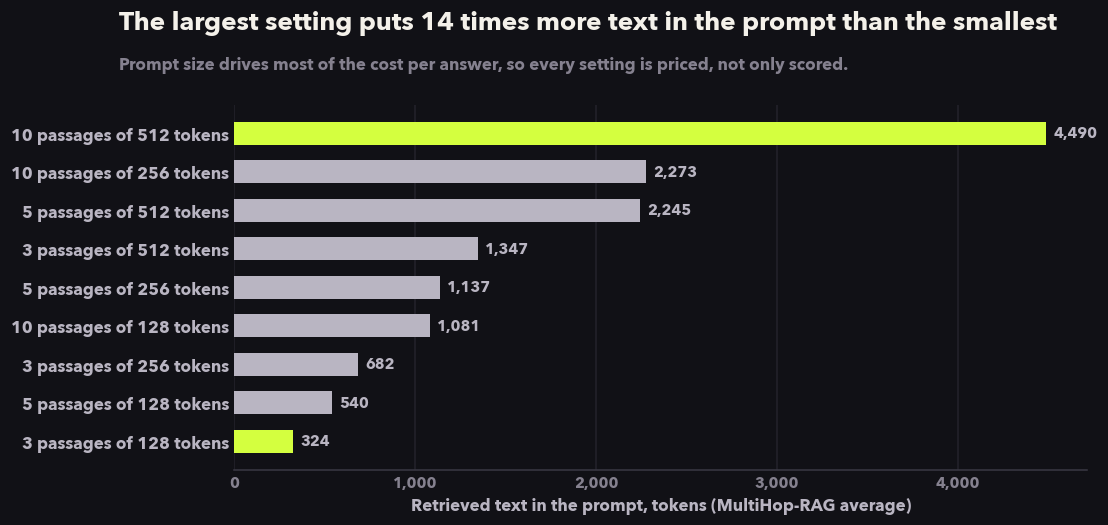

In [11]:
avg_tokens = {size: chunks["multihop_rag", size]["tokens"].mean() for size in CHUNK_SIZES}
combos = [(size, k, size_k) for size in CHUNK_SIZES for k in TOP_K for size_k in [avg_tokens[size] * k]]
combos.sort(key=lambda c: c[2])
spread = combos[-1][2] / combos[0][2]

fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(combos))
colors = [style.HIGHLIGHT if c in (combos[0], combos[-1]) else style.INK_2 for c in combos]
ax.barh(y, [c[2] for c in combos], color=colors, height=0.6)
for i, c in enumerate(combos):
    ax.text(c[2] + 40, i, f"{c[2]:,.0f}", va="center", color=style.INK_2, fontsize=10)
ax.set_yticks(y, [f"{c[1]} passages of {c[0]} tokens" for c in combos])
ax.set_xlabel("Retrieved text in the prompt, tokens (MultiHop-RAG average)")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
style.headline(fig, f"The largest setting puts {spread:.0f} times more text in the prompt than the smallest",
               "Prompt size drives most of the cost per answer, so every setting is priced, not only scored.")
fig.subplots_adjust(top=0.8)
style.save(fig, "prompt_size")
plt.show()

## What this tells us

- **Guessing is a real competitor on MultiHop-RAG.** Always giving the most common answer for each question type gets 47% of answerable questions right. Results are reported against that floor and by question type.
- **The sample is big enough for differences of about 7 points** on MultiHop-RAG and 8 on Natural Questions. Anything smaller is reported as not distinguishable.
- **all-MiniLM-L6-v2 cannot read nine in ten 512-token chunks to the end.** The study keeps that setup because people run it, and notebook 02 measures what it costs.
- **Prompt size varies 14 fold across the grid**, so a setting that buys a little accuracy can cost a lot. Notebook 05 puts a price on every configuration.

Next: [notebook 02](02_retrieval.ipynb) measures how well each configuration finds the evidence.